# Penguins classification

In this notebook we create a model to classify penguin species. There are 3 species of penguin:

<img src="https://wagon-public-datasets.s3.amazonaws.com/05-Machine-Learning/01-Fundamentals-of-Machine-Learning/palmer-penguins.png" width=1000>



## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector

from sklearn.linear_model import LogisticRegression

👉 Run the cell below to make sure all our transformers output Pandas DataFrames, and not NumPy arrays.

In [2]:
from sklearn import set_config
set_config(transform_output="pandas")

## Load the dataset

In [3]:
penguin_df = sns.load_dataset('penguins')
penguin_df.dropna(inplace=True)

penguin_df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


❓What are the characteristics of the penguins?

<img src='https://wagon-public-datasets.s3.amazonaws.com/05-Machine-Learning/gentoo.png' width=700 alt="Image of a penguin highlighting bill and flipper">

❓How many species of penguin are there in this dataset?

In [4]:
penguin_df['species'].nunique()

3

❓How many observations for each species are there in the dataset?

In [5]:
penguin_df['species'].value_counts()

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

In [6]:
len(penguin_df)

333

## Data visualization

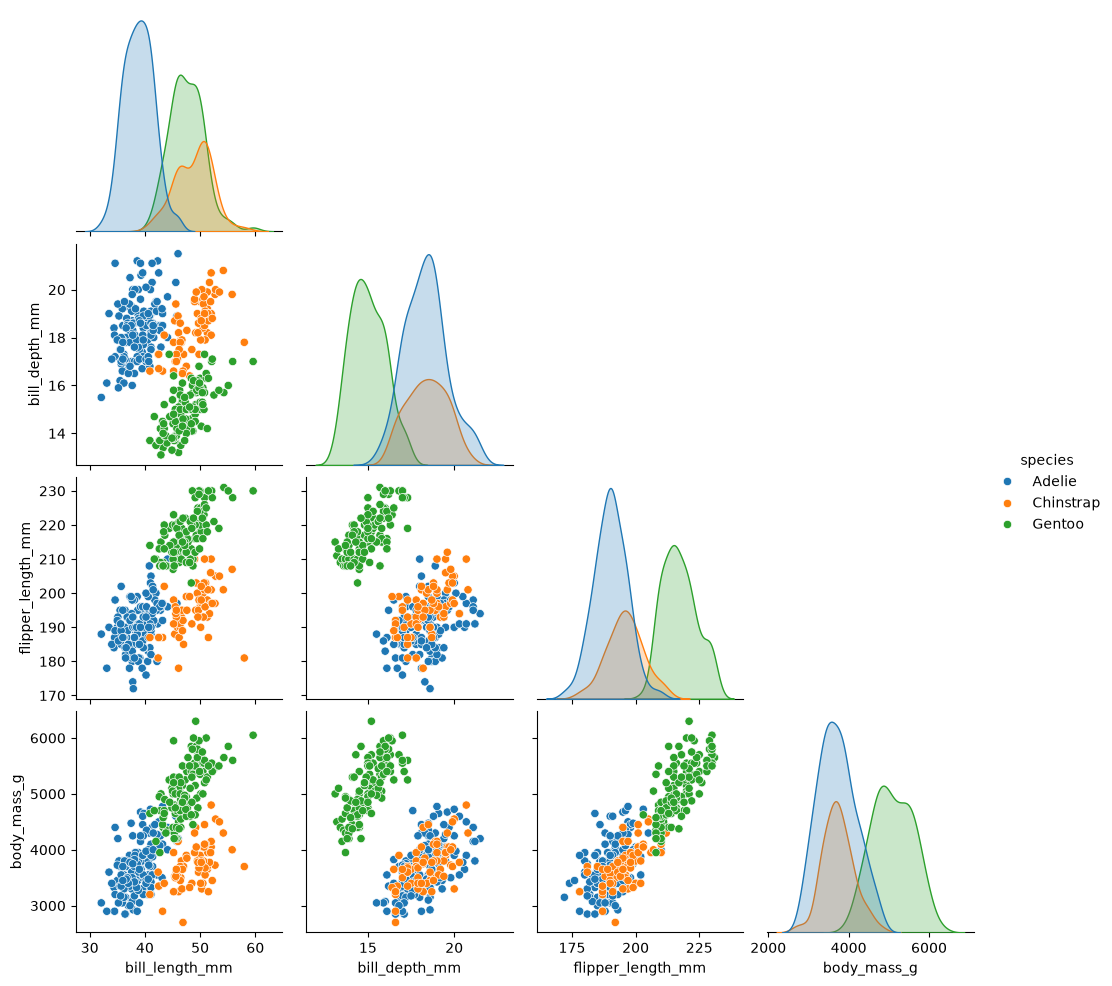

In [7]:
sns.pairplot(penguin_df, hue="species", corner=True);

The **gentoo** species seems to have clearly longer flippers than the other 2 species.

In [8]:
penguin_df.groupby(["island", "species"]).size() \
          .reset_index() \
          .pivot(columns=['species'], index=['island'], values=0) \
          .fillna(0).astype(int)

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,119
Dream,55,68,0
Torgersen,47,0,0


Chinstrap and Gentoe only live on one island. Torgersen only has Adelie. All-in-all there is no one-to-one relation though.

In [9]:
penguin_df.groupby(["sex", "species"]).size() \
          .reset_index() \
          .pivot(columns=['species'], index=['sex'], values=0) \
          .fillna(0).astype(int)

species,Adelie,Chinstrap,Gentoo
sex,,,
Female,73,34,58
Male,73,34,61


## Train-test-split

In [10]:
X = penguin_df.drop(columns=['species'])
y = penguin_df['species']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

## Preprocessing

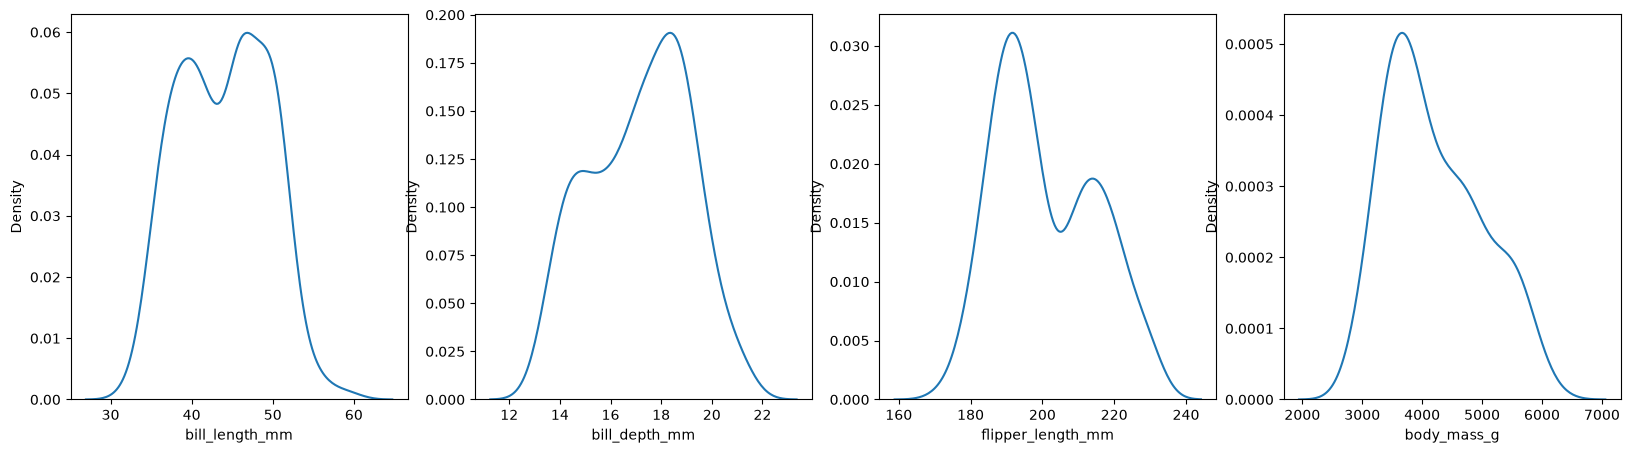

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20,5))
for i, col in enumerate(['bill_length_mm','bill_depth_mm', 'flipper_length_mm', 'body_mass_g']):
    sns.kdeplot(data=penguin_df, x=col, ax=axes[i])

In [12]:
preprocessor = ColumnTransformer(
    [
        (
            "num",
            StandardScaler(),
            make_column_selector(dtype_include="number"),
        ),
        (
            "cat",
            OneHotEncoder(drop="if_binary", sparse_output=False),
            make_column_selector(dtype_include="object"),
        ),
    ]
)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## Modeling

In [13]:
model = LogisticRegression()

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', model)
    ])

cv_score = cross_val_score(pipeline, X_train, y_train, cv=5, scoring='accuracy')

cv_score.mean()

np.float64(0.9962264150943396)

In [17]:
final_pipeline = pipeline.fit(X_train, y_train)

y_pred = final_pipeline.predict(X_test)

accuracy_score(y_test, y_pred)

0.9850746268656716

In [15]:
import os
os.getcwd()

'/home/julien/code/Maneixx/zoologist/notebooks'

In [18]:
import joblib
with open('../models/pipeline_logrerg.joblib', 'wb') as f:
    joblib.dump(final_pipeline, f)

# 🏁 